# Week 10 — Dasar-Dasar Deteksi Obyek
**Pengolahan Citra dan Visi Komputer** — Mochamad Yunan Helmy Affandi (TI-3A / 13)

## D1. Praktikum Deteksi Obyek Dasar
Metode yang digunakan:
1. Template Matching (6 metode OpenCV + implementasi manual multi-objek)
2. Edge Detection (Sobel, Canny, Laplacian)
3. Corner Detection (Harris, Shi-Tomasi)
4. Grid Detection (Hough Transform)
5. Contour Detection (findContours)

In [ ]:
import cv2 as cv
import numpy as np
from matplotlib import pyplot as plt

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

## 2. Template Matching — 6 metode OpenCV


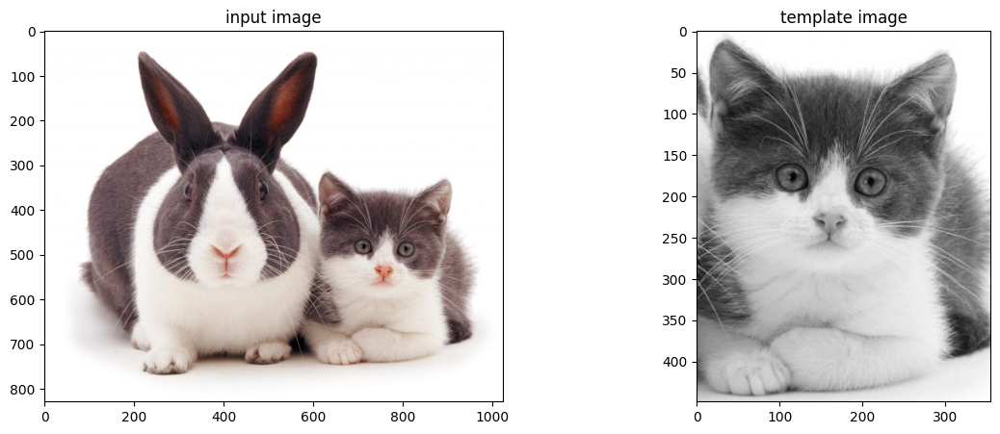

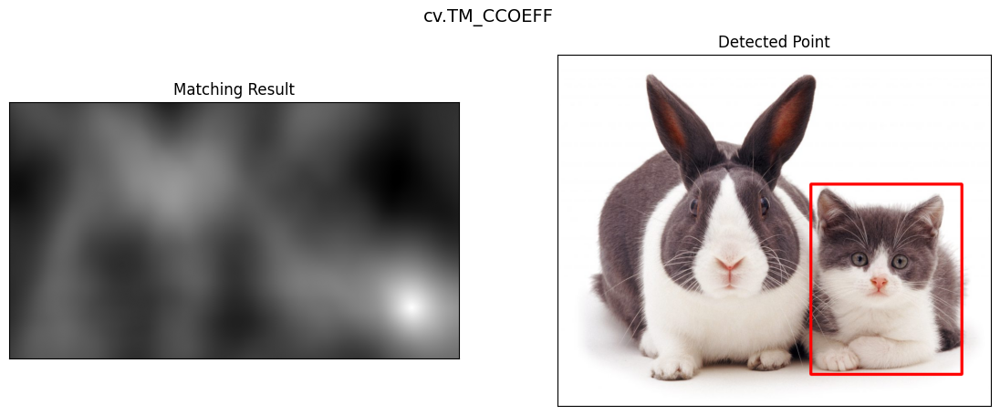

cv.TM_CCOEFF           lokasi kiri-atas = (597, 305)


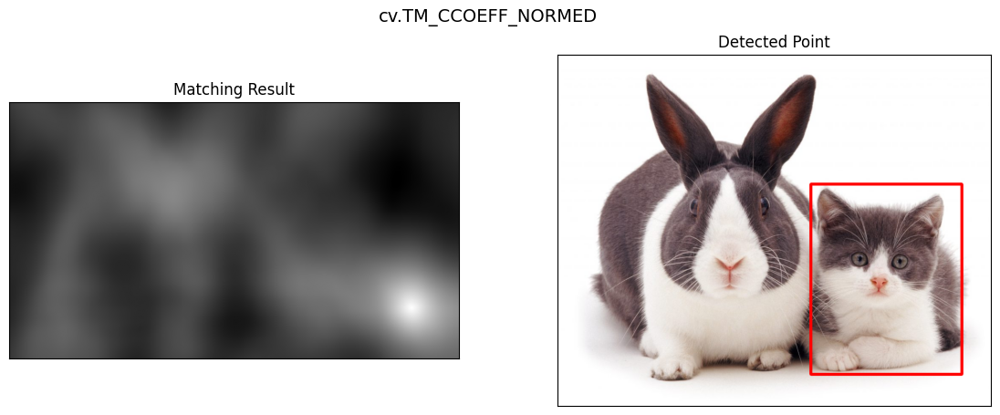

cv.TM_CCOEFF_NORMED    lokasi kiri-atas = (597, 305)


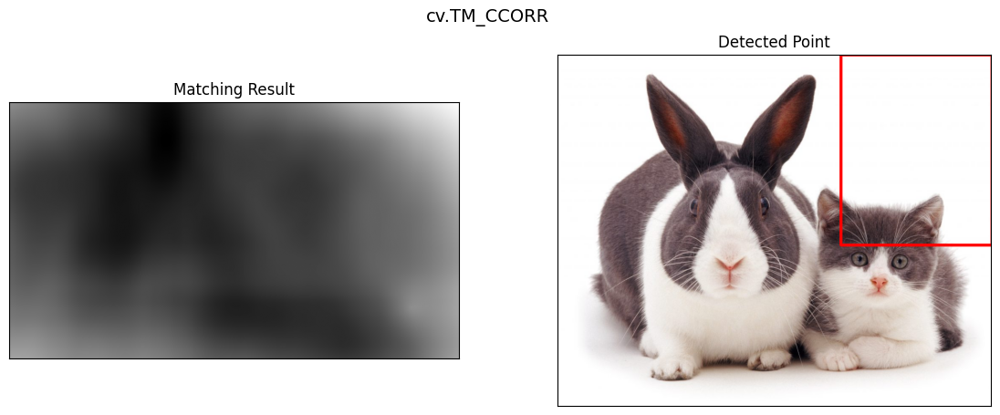

cv.TM_CCORR            lokasi kiri-atas = (668, 0)


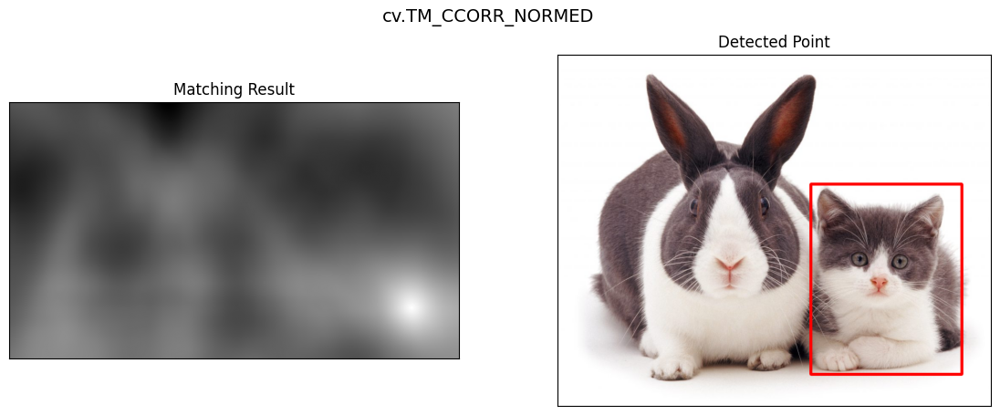

cv.TM_CCORR_NORMED     lokasi kiri-atas = (597, 305)


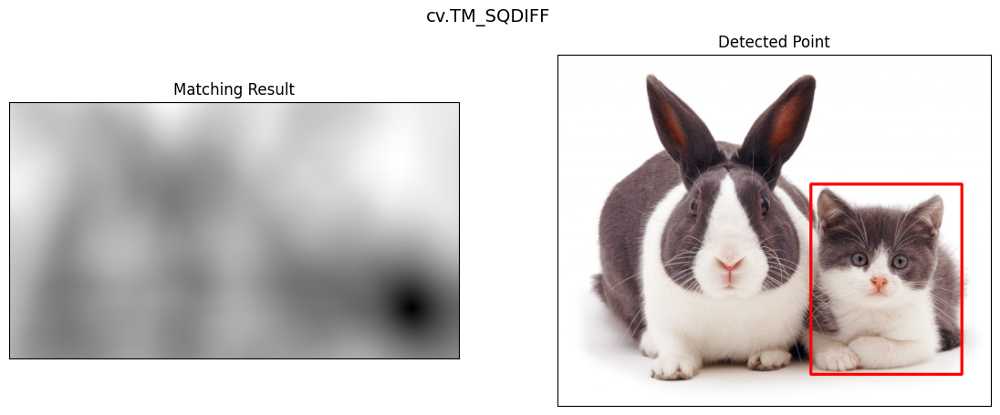

cv.TM_SQDIFF           lokasi kiri-atas = (597, 305)


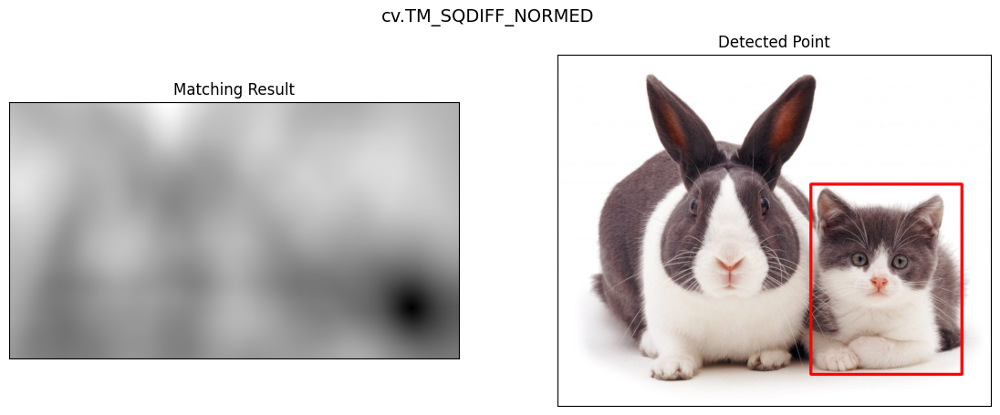

cv.TM_SQDIFF_NORMED    lokasi kiri-atas = (597, 305)


In [ ]:
img = cv.imread(cari('cats_and_bunnies.jpg'))
templ = cv.imread(cari('cat2_templatejpg.jpg', 'cat2_template.jpg'))
h, w = templ.shape[:2]

plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1), plt.imshow(rgb(img)), plt.title('input image')
plt.subplot(1, 2, 2), plt.imshow(cv.cvtColor(templ, cv.COLOR_BGR2GRAY), cmap='gray'), plt.title('template image')
plt.show()

methods = ['cv.TM_CCOEFF', 'cv.TM_CCOEFF_NORMED', 'cv.TM_CCORR',
           'cv.TM_CCORR_NORMED', 'cv.TM_SQDIFF', 'cv.TM_SQDIFF_NORMED']

for nama in methods:
    method = eval(nama)
    res = cv.matchTemplate(img, templ, method)
    min_val, max_val, min_loc, max_loc = cv.minMaxLoc(res)
    top_left = min_loc if method in [cv.TM_SQDIFF, cv.TM_SQDIFF_NORMED] else max_loc
    bottom_right = (top_left[0] + w, top_left[1] + h)

    hasil = rgb(img).copy()
    cv.rectangle(hasil, top_left, bottom_right, (255, 0, 0), 5)

    plt.figure(figsize=(14, 5))
    plt.subplot(1, 2, 1), plt.imshow(res, cmap='gray'), plt.title('Matching Result'), plt.xticks([]), plt.yticks([])
    plt.subplot(1, 2, 2), plt.imshow(hasil), plt.title('Detected Point'), plt.xticks([]), plt.yticks([])
    plt.suptitle(nama, fontsize=14)
    plt.show()
    print(f'{nama:22s} lokasi kiri-atas = {top_left}')

## 3. Template Matching tanpa library OpenCV (multiple object)


Selisih maksimum NCC manual vs OpenCV: 0.0447
threshold 0.50 -> 3 objek
threshold 0.45 -> 6 objek
threshold 0.40 -> 7 objek
threshold 0.35 -> 12 objek
threshold 0.30 -> 18 objek
threshold 0.25 -> 26 objek
Objek terdeteksi (skor >= 0.4): 7
  posisi (x=393, y=204)  skor=0.964
  posisi (x=436, y=267)  skor=0.576
  posisi (x=445, y=346)  skor=0.520
  posisi (x=411, y=415)  skor=0.499
  posisi (x=345, y=460)  skor=0.475
  posisi (x=270, y=465)  skor=0.471
  posisi (x=248, y=125)  skor=0.429


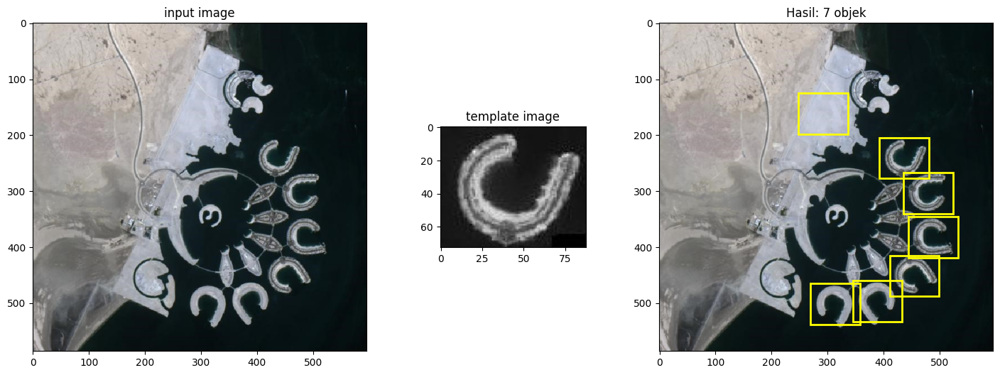

In [ ]:
from matplotlib.patches import Rectangle

def ke_gray(img_bgr):
    b, g, r = img_bgr[..., 0], img_bgr[..., 1], img_bgr[..., 2]
    return (0.299 * r + 0.587 * g + 0.114 * b).astype(np.float64)

def integral(a):
    return np.pad(a, ((1, 0), (1, 0))).cumsum(0).cumsum(1)

def jumlah_jendela(ii, th, tw):
    return ii[th:, tw:] - ii[:-th, tw:] - ii[th:, :-tw] + ii[:-th, :-tw]

def ncc_manual(I, T):
    H, W = I.shape
    th, tw = T.shape
    n = th * tw
    Tz = T - T.mean()
    fshape = (H + th - 1, W + tw - 1)
    corr = np.fft.irfft2(np.fft.rfft2(I, fshape) * np.fft.rfft2(Tz[::-1, ::-1], fshape), fshape)
    corr = corr[th - 1:H, tw - 1:W]                       # sum(T' * I) pada tiap posisi
    s  = jumlah_jendela(integral(I), th, tw)
    s2 = jumlah_jendela(integral(I * I), th, tw)
    var_I = np.maximum(s2 - s * s / n, 1e-8)              # sum(I'^2)
    return corr / np.sqrt(var_I * (Tz ** 2).sum())

def cari_banyak(R, thr, th, tw, maks=5000):
    ys, xs = np.where(R >= thr)
    urut = np.argsort(R[ys, xs])[::-1][:maks]
    kotak = []
    for k in urut:
        y, x = ys[k], xs[k]
        if all(abs(y - by) > th * 0.5 or abs(x - bx) > tw * 0.5 for by, bx, _ in kotak):
            kotak.append((y, x, R[y, x]))
    return kotak

src = cv.imread(cari('bahrain.jpg'))
tpl = cv.imread(cari('bahrain-template.jpg', 'bahrain_template.jpg'))
I, T = ke_gray(src), ke_gray(tpl)
th, tw = T.shape
R = ncc_manual(I, T)

# verifikasi: harus sama dengan cv.TM_CCOEFF_NORMED
R_cv = cv.matchTemplate(cv.cvtColor(src, cv.COLOR_BGR2GRAY), cv.cvtColor(tpl, cv.COLOR_BGR2GRAY), cv.TM_CCOEFF_NORMED)
print('Selisih maksimum NCC manual vs OpenCV:', round(float(np.abs(R - R_cv).max()), 4))

for thr in [0.5, 0.45, 0.4, 0.35, 0.3, 0.25]:
    print(f'threshold {thr:.2f} -> {len(cari_banyak(R, thr, th, tw))} objek')

THRESHOLD = 0.40   # dipilih dari sweep: 0.40 memberi 7 objek tanpa salah deteksi
kotak = cari_banyak(R, THRESHOLD, th, tw)
print(f'Objek terdeteksi (skor >= {THRESHOLD}):', len(kotak))
for y, x, s in kotak:
    print(f'  posisi (x={x}, y={y})  skor={s:.3f}')

fig, ax = plt.subplots(1, 3, figsize=(18, 6), gridspec_kw={'width_ratios': [3, 1.2, 3]})
ax[0].imshow(rgb(src)); ax[0].set_title('input image')
ax[1].imshow(T, cmap='gray'); ax[1].set_title('template image')
ax[2].imshow(rgb(src)); ax[2].set_title(f'Hasil: {len(kotak)} objek')
for y, x, s in kotak:
    ax[2].add_patch(Rectangle((x, y), tw, th, fill=False, edgecolor='yellow', linewidth=2))
plt.show()

## 4. Edge Detection — Sobel, Canny, Laplacian (car-park.jpg)

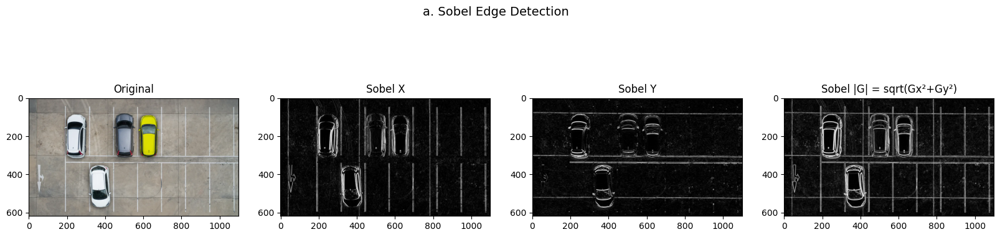

In [ ]:
car = cv.imread(cari('car-park.jpg', 'car_park.jpg'))
gray = cv.cvtColor(car, cv.COLOR_BGR2GRAY)
blur = cv.GaussianBlur(gray, (3, 3), 0)

# a. Sobel
sobel_x = cv.Sobel(blur, cv.CV_64F, 1, 0, ksize=3)
sobel_y = cv.Sobel(blur, cv.CV_64F, 0, 1, ksize=3)
sobel = cv.convertScaleAbs(cv.magnitude(sobel_x, sobel_y))

plt.figure(figsize=(20, 5))
for i, (im, t) in enumerate([(rgb(car), 'Original'), (cv.convertScaleAbs(sobel_x), 'Sobel X'),
                             (cv.convertScaleAbs(sobel_y), 'Sobel Y'), (sobel, 'Sobel |G| = sqrt(Gx²+Gy²)')]):
    plt.subplot(1, 4, i + 1); plt.imshow(im, cmap=None if im.ndim == 3 else 'gray'); plt.title(t)
plt.suptitle('a. Sobel Edge Detection', fontsize=14); plt.show()

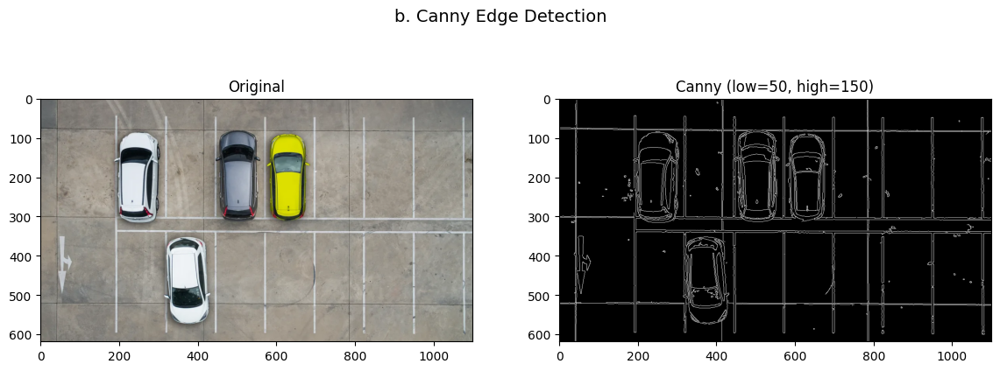

In [ ]:
# b. Canny (Gaussian -> gradien Sobel -> non-maximum suppression -> hysteresis)
canny = cv.Canny(blur, 50, 150)

plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1), plt.imshow(rgb(car)), plt.title('Original')
plt.subplot(1, 2, 2), plt.imshow(canny, cmap='gray'), plt.title('Canny (low=50, high=150)')
plt.suptitle('b. Canny Edge Detection', fontsize=14); plt.show()

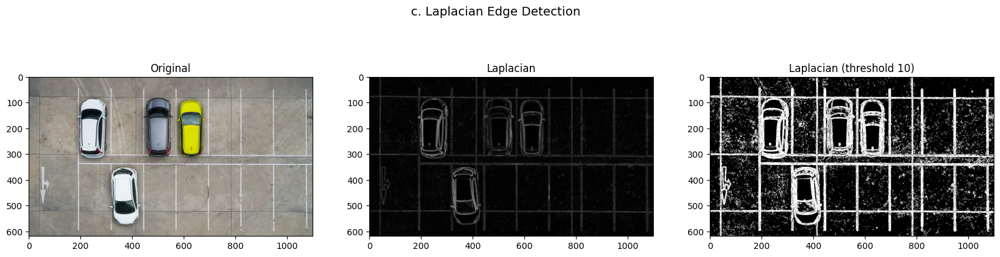

In [ ]:
# c. Laplacian (dihaluskan Gaussian dulu karena Laplacian sangat sensitif noise)
lap = cv.Laplacian(cv.GaussianBlur(gray, (5, 5), 0), cv.CV_64F, ksize=3)
lap = cv.convertScaleAbs(lap)
_, lap_bin = cv.threshold(lap, 10, 255, cv.THRESH_BINARY)

plt.figure(figsize=(20, 5))
plt.subplot(1, 3, 1), plt.imshow(rgb(car)), plt.title('Original')
plt.subplot(1, 3, 2), plt.imshow(lap, cmap='gray'), plt.title('Laplacian')
plt.subplot(1, 3, 3), plt.imshow(lap_bin, cmap='gray'), plt.title('Laplacian (threshold 10)')
plt.suptitle('c. Laplacian Edge Detection', fontsize=14); plt.show()

## 5. Corner Detection — Harris dan Shi-Tomasi (chess-board.jpg)

Piksel sudut Harris: 2238
Sudut Shi-Tomasi: 100


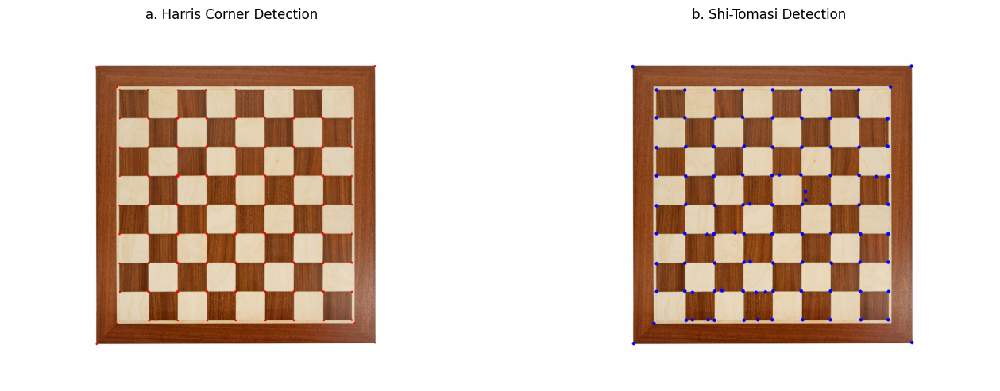

In [ ]:
chess = cv.imread(cari('chess-board.jpg', 'chessboard.jpg', 'chess'))
gray_c = np.float32(cv.cvtColor(chess, cv.COLOR_BGR2GRAY))

# a. Harris: cornerHarris(src, blockSize, ksize, k)
dst = cv.cornerHarris(gray_c, 2, 3, 0.04)
dst = cv.dilate(dst, None)                    # perbesar titik agar terlihat
harris = chess.copy()
harris[dst > 0.01 * dst.max()] = [0, 0, 255]
print('Piksel sudut Harris:', int((dst > 0.01 * dst.max()).sum()))

# b. Shi-Tomasi: goodFeaturesToTrack(img, maxCorners, qualityLevel, minDistance)
corners = cv.goodFeaturesToTrack(np.uint8(gray_c), 100, 0.01, 10)
shi = chess.copy()
for c in np.intp(corners):
    x, y = c.ravel()
    cv.circle(shi, (int(x), int(y)), 4, (255, 0, 0), -1)
print('Sudut Shi-Tomasi:', len(corners))

plt.figure(figsize=(16, 8))
plt.subplot(1, 2, 1), plt.imshow(rgb(harris)), plt.title('a. Harris Corner Detection'), plt.axis('off')
plt.subplot(1, 2, 2), plt.imshow(rgb(shi)), plt.title('b. Shi-Tomasi Detection'), plt.axis('off')
plt.show()

## 6. Grid Detection — Hough Transform (sudoku.jpg)
Tahapan sesuai teori: Canny → dilasi → erosi → HoughLines → gabungkan garis yang mirip.

Threshold HoughLines terpilih: 210
Arah dominan: 160° dan 70° | garis diagonal dibuang: 5
Garis Hough mentah: 89 | setelah digabung: 19


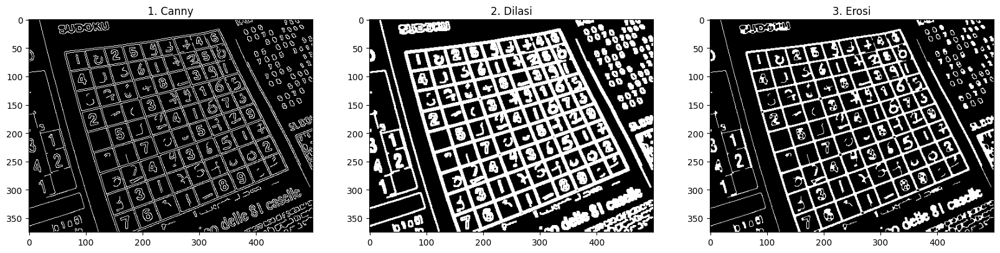

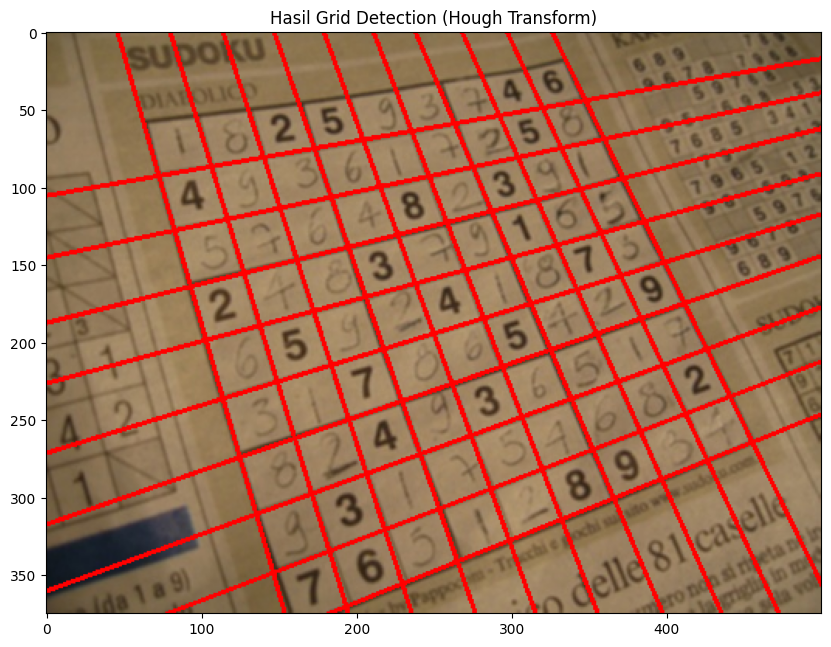

In [ ]:
sudoku = cv.imread(cari('sudoku.jpg'))
gray_s = cv.cvtColor(sudoku, cv.COLOR_BGR2GRAY)

edges = cv.Canny(gray_s, 90, 150, apertureSize=3)                 # 1. Canny
kernel = np.ones((3, 3), np.uint8)
edges_d = cv.dilate(edges, kernel, iterations=1)                   # 2. dilasi: gabungkan 2 tepi garis grid
edges_e = cv.erode(edges_d, kernel, iterations=1)                  # 3. erosi: tipiskan lagi

def gabung_garis(lines, rho_th=20, theta_th=np.pi / 18):           # 5. gabungkan garis mirip
    hasil = []
    for rho, theta in lines[:, 0]:
        if all(abs(rho - r) > rho_th or abs(theta - t) > theta_th for r, t in hasil):
            hasil.append((rho, theta))
    return hasil

# 4. Hough: threshold dinaikkan bertahap sampai jumlah garis ~ grid sudoku (10 + 10 = 20 garis)
for HOUGH_THR in range(150, 400, 10):
    lines = cv.HoughLines(edges_e, 1, np.pi / 180, HOUGH_THR)
    garis = gabung_garis(lines) if lines is not None else []
    if len(garis) <= 24:
        break
print('Threshold HoughLines terpilih:', HOUGH_THR)

# Filter tambahan: grid hanya punya 2 arah dominan. Garis yang sudutnya jauh dari kedua arah itu (diagonal palsu) dibuang.
sudut = np.array([t for _, t in garis])
hist, bins = np.histogram(sudut, bins=36, range=(0, np.pi))
arah1 = bins[np.argmax(hist)]
hist2 = hist.copy(); hist2[np.abs((bins[:-1] - arah1 + np.pi / 2) % np.pi - np.pi / 2) < np.pi / 6] = 0
arah2 = bins[np.argmax(hist2)]
def dekat(t, a, tol=np.pi / 18):
    return abs((t - a + np.pi / 2) % np.pi - np.pi / 2) < tol
sebelum = len(garis)
garis = [(r, t) for r, t in garis if dekat(t, arah1) or dekat(t, arah2)]
print(f'Arah dominan: {np.degrees(arah1):.0f}° dan {np.degrees(arah2):.0f}° | garis diagonal dibuang: {sebelum - len(garis)}')
print('Garis Hough mentah:', 0 if lines is None else len(lines), '| setelah digabung:', len(garis))

grid = rgb(sudoku).copy()
for rho, theta in garis:
    a, b = np.cos(theta), np.sin(theta)
    x0, y0 = a * rho, b * rho
    p1 = (int(x0 + 2000 * (-b)), int(y0 + 2000 * a))
    p2 = (int(x0 - 2000 * (-b)), int(y0 - 2000 * a))
    cv.line(grid, p1, p2, (255, 0, 0), 2)

plt.figure(figsize=(20, 5))
for i, (im, t) in enumerate([(edges, '1. Canny'), (edges_d, '2. Dilasi'), (edges_e, '3. Erosi')]):
    plt.subplot(1, 3, i + 1); plt.imshow(im, cmap='gray'); plt.title(t)
plt.show()
plt.figure(figsize=(10, 8)); plt.imshow(grid); plt.title('Hasil Grid Detection (Hough Transform)'); plt.show()

## 7. Contour Detection — findContours (laptop.jpg)
Tahapan: citra → biner (Canny + dilasi) → \`findContours\` → \`drawContours\`.

Total kontur: 73 | kontur dengan area > 4915 px: 12


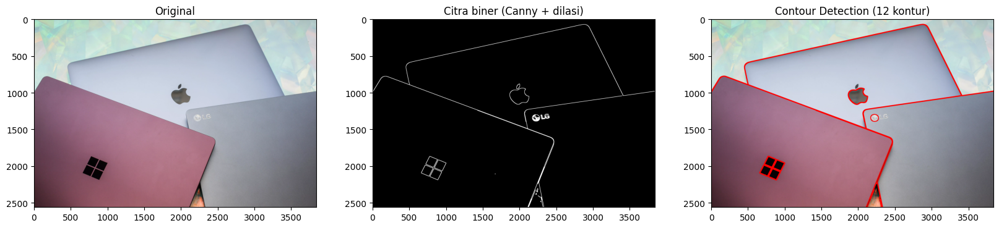

In [ ]:
laptop = cv.imread(cari('laptop.jpg'))
gray_l = cv.cvtColor(laptop, cv.COLOR_BGR2GRAY)
blur_l = cv.GaussianBlur(gray_l, (7, 7), 0)

edges_l = cv.Canny(blur_l, 30, 100)
edges_l = cv.dilate(edges_l, np.ones((5, 5), np.uint8), iterations=1)   # tutup celah tepi

contours, hierarchy = cv.findContours(edges_l, cv.RETR_TREE, cv.CHAIN_APPROX_SIMPLE)
min_area = 0.0005 * laptop.shape[0] * laptop.shape[1]
besar = [c for c in contours if cv.contourArea(c) > min_area]
print('Total kontur:', len(contours), '| kontur dengan area >', int(min_area), 'px:', len(besar))

hasil_l = rgb(laptop).copy()
tebal = max(2, laptop.shape[1] // 400)
cv.drawContours(hasil_l, besar, -1, (255, 0, 0), tebal)

plt.figure(figsize=(20, 7))
plt.subplot(1, 3, 1), plt.imshow(rgb(laptop)), plt.title('Original')
plt.subplot(1, 3, 2), plt.imshow(edges_l, cmap='gray'), plt.title('Citra biner (Canny + dilasi)')
plt.subplot(1, 3, 3), plt.imshow(hasil_l), plt.title(f'Contour Detection ({len(besar)} kontur)')
plt.show()

---
# D2. Praktikum Feature Matching dan Face Detection


## 8. Face Detection untuk gambar lain di \`/images/facedet\`

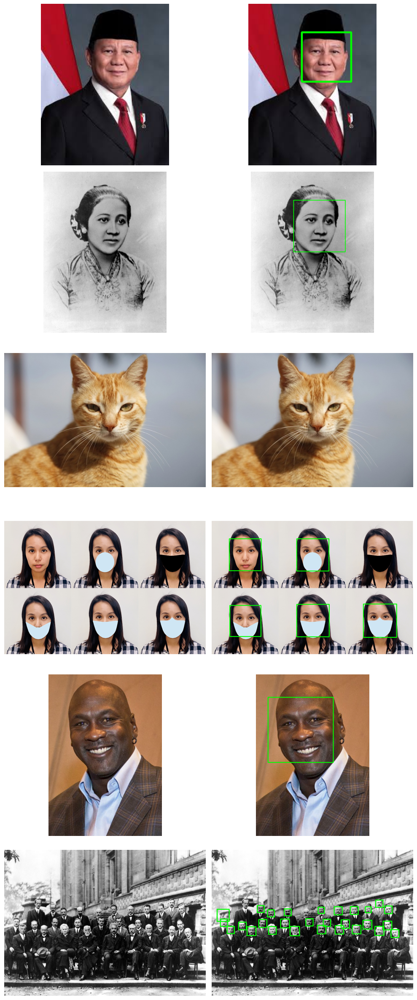

In [14]:
FACEDET = os.path.dirname(cari('solvayconf.jpg'))
daftar = ['prabowo.jpg', 'kartini.jpg', 'mycat.jpg', 'mask.png', 'mjordan.jpg', 'solvayconf.jpg']

plt.figure(figsize=(10, 4 * len(daftar)))
for i, nama in enumerate(daftar):
    img = cv.imread(os.path.join(FACEDET, nama))
    out, roi = deteksi(img, cascade_wajah)
    plt.subplot(len(daftar), 2, 2 * i + 1), plt.imshow(rgb(img)), plt.axis('off')
    plt.subplot(len(daftar), 2, 2 * i + 2), plt.imshow(rgb(out)), plt.axis('off')
plt.tight_layout()
plt.show()

## 9. Deteksi wajah kucing


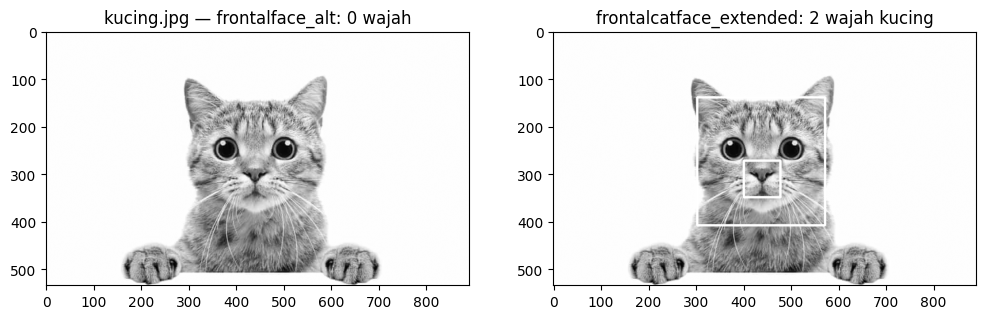

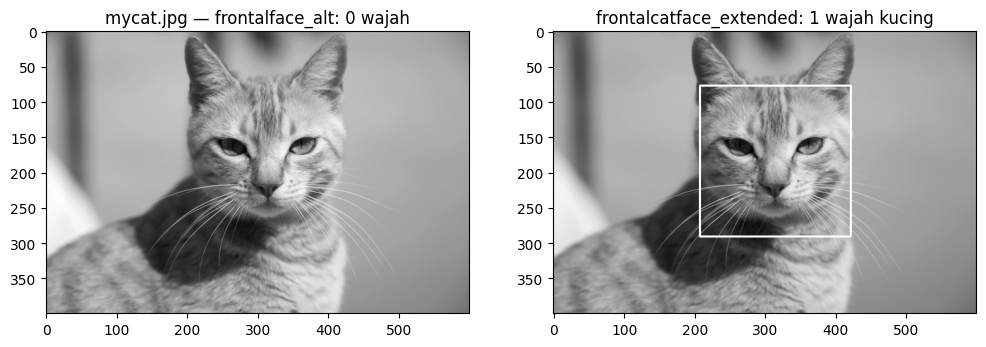

In [ ]:
cat_cascade = haar('haarcascade_frontalcatface_extended.xml')

for nama in ['kucing.jpg', 'mycat.jpg']:
    p = os.path.join(FACEDET, nama)
    if not os.path.exists(p):
        continue
    img = cv.imread(p)
    _, roi_manusia = deteksi(img, cascade_wajah)
    out, roi = deteksi(img, cat_cascade, warna=(255, 255, 255), scaleFactor=1.05, minNeighbors=3, minSize=(60, 60))
    plt.figure(figsize=(12, 5))
    plt.subplot(1, 2, 1), plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2GRAY), cmap='gray'), plt.title(f'{nama} — frontalface_alt: {len(roi_manusia)} wajah')
    plt.subplot(1, 2, 2), plt.imshow(cv.cvtColor(out, cv.COLOR_BGR2GRAY), cmap='gray'), plt.title(f'frontalcatface_extended: {len(roi)} wajah kucing')
    plt.show()

## 10. Eyes detection pada wajah Pak Prabowo


Wajah di (83,44) -> 2 mata terdeteksi (minNeighbors=5)


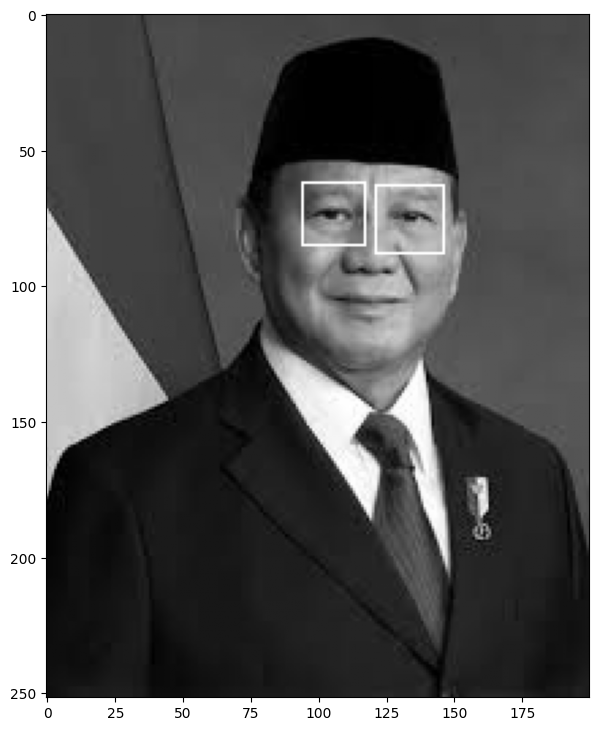

In [ ]:
eye_cascade = haar('haarcascade_eye.xml')
img = cv.imread(cari('prabowo.jpg'))
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
hasil = gray.copy()

for (x, y, w, h) in cascade_wajah.detectMultiScale(gray):
    roi = gray[y:y + int(h * 0.6), x:x + w]
    for mn in [5, 3, 1]:
        eyes = eye_cascade.detectMultiScale(roi, scaleFactor=1.05, minNeighbors=mn, minSize=(w // 8, w // 8))
        if len(eyes) >= 2:
            break
    eyes = sorted(eyes, key=lambda e: -e[2])[:2]
    for (ex, ey, ew, eh) in eyes:
        cv.rectangle(hasil, (x + ex, y + ey), (x + ex + ew, y + ey + eh), 255, 1)
    print(f'Wajah di ({x},{y}) -> {len(eyes)} mata terdeteksi (minNeighbors={mn})')

plt.figure(figsize=(7, 9)); plt.imshow(hasil, cmap='gray'); plt.show()

## 11. Deteksi senyuman pada gambar people


Wajah  1 (x=  25, y=  26)  skor senyum = 10  -> -
Wajah  2 (x= 258, y=  27)  skor senyum = 180  -> SENYUM
Wajah  3 (x= 384, y=  47)  skor senyum =  0  -> -
Wajah  4 (x= 520, y=  43)  skor senyum = 10  -> -
Wajah  5 (x=  20, y= 179)  skor senyum = 400  -> SENYUM
Wajah  6 (x= 140, y= 172)  skor senyum = 40  -> -
Wajah  7 (x= 254, y= 181)  skor senyum = 320  -> SENYUM
Wajah  8 (x= 380, y= 176)  skor senyum = 150  -> SENYUM
Wajah  9 (x= 505, y= 168)  skor senyum =  0  -> -


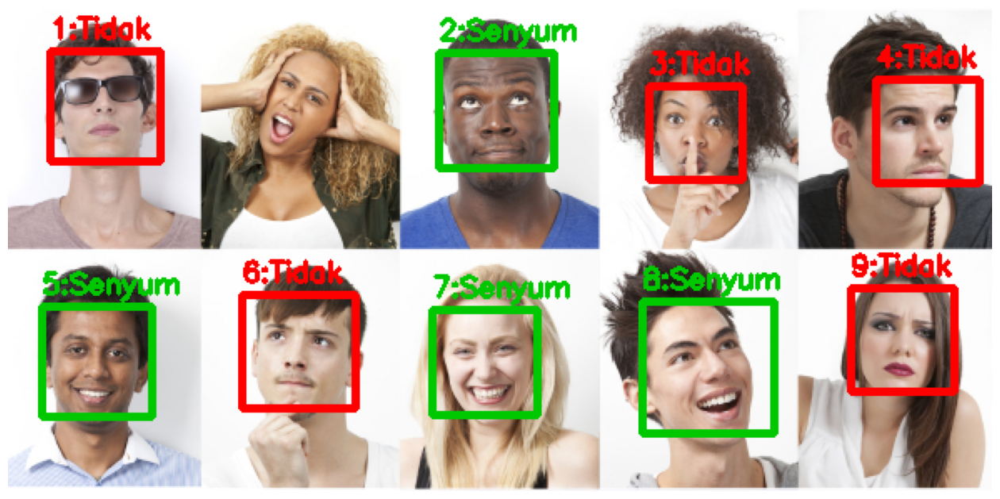

In [ ]:
smile_cascade = haar('haarcascade_smile.xml')
img = cv.imread(cari('people.jpg'))
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
out = img.copy()
faces = cascade_wajah.detectMultiScale(gray, scaleFactor=1.05, minNeighbors=4, minSize=(40, 40))
faces = sorted(faces, key=lambda f: (f[1] // 100, f[0]))

def skor_senyum(face_gray):

    f = cv.resize(face_gray, (200, int(200 * face_gray.shape[0] / face_gray.shape[1])))
    f = cv.equalizeHist(f)
    mulut = f[f.shape[0] * 55 // 100:, :]
    skor = 0
    for mn in range(10, 401, 10):
        if len(smile_cascade.detectMultiScale(mulut, scaleFactor=1.1, minNeighbors=mn, minSize=(60, 25))):
            skor = mn
    return skor

SKOR_MIN = 120
for no, (x, y, w, h) in enumerate(faces, 1):
    s = skor_senyum(gray[y:y + h, x:x + w])
    senyum = s >= SKOR_MIN
    warna = (0, 200, 0) if senyum else (0, 0, 255)
    cv.rectangle(out, (x, y), (x + w, y + h), warna, 3)
    cv.putText(out, f'{no}:{"Senyum" if senyum else "Tidak"}', (x, max(15, y - 8)), cv.FONT_HERSHEY_SIMPLEX, 0.55, warna, 2)
    print(f'Wajah {no:2d} (x={x:4d}, y={y:4d})  skor senyum = {s:2d}  -> {"SENYUM" if senyum else "-"}')

plt.figure(figsize=(16, 9)); plt.imshow(rgb(out)); plt.axis('off'); plt.show()

**Analisis:** Wajah dinormalisasi ke lebar 200 px dan histogramnya diratakan, lalu *skor senyum* = `minNeighbors` tertinggi yang masih menghasilkan deteksi senyum di area mulut. Dengan ambang skor 120, ketiga wajah yang jelas tersenyum (5, 7, 8) terdeteksi, dan wajah netral/tertutup lainnya ditolak. Masih ada **1 false positive** (wajah 2): bibirnya tertutup tapi melebar, sehingga pola terang-gelapnya mirip senyum. Satu wajah (perempuan berteriak) juga tidak terdeteksi oleh frontal face cascade karena kepalanya miring dan tangan menutupi sebagian wajah. Ini menunjukkan keterbatasan Haar Cascade untuk ekspresi, yang di aplikasi nyata biasanya diganti CNN.

## 12. Face Tracking menggunakan Google Colab (webcam)


<IPython.core.display.Javascript object>

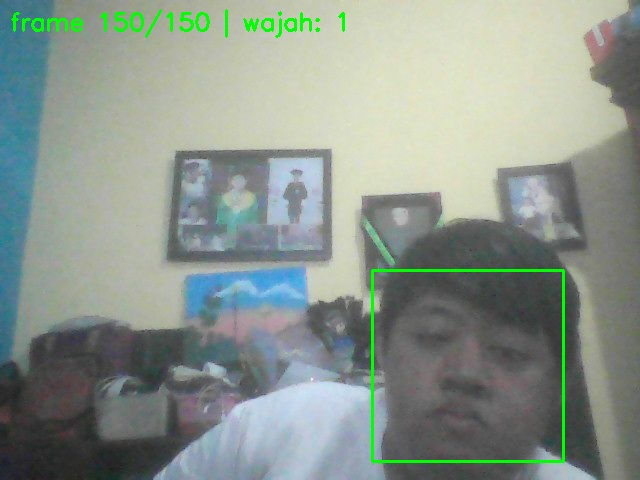

In [6]:
import cv2 as cv
import os
JALANKAN_KAMERA = True   # ganti True untuk mencoba face tracking
JUMLAH_FRAME = 150

# Memastikan cascade_wajah dan fungsi deteksi terdefinisi secara independen di sel ini
try:
    HAAR_DIR = os.path.dirname(cari('haarcascade_frontalface_alt.xml'))
except Exception:
    HAAR_DIR = cv.data.haarcascades

p_cascade = os.path.join(HAAR_DIR, 'haarcascade_frontalface_alt.xml')
if not os.path.exists(p_cascade):
    p_cascade = os.path.join(cv.data.haarcascades, 'haarcascade_frontalface_alt.xml')
cascade_wajah = cv.CascadeClassifier(p_cascade)

def deteksi(img_bgr, cascade, warna=(0, 255, 0), **kw):
    gray = cv.cvtColor(img_bgr, cv.COLOR_BGR2GRAY)
    roi = cascade.detectMultiScale(gray, **kw)
    out = img_bgr.copy()
    tebal = max(2, img_bgr.shape[1] // 250)
    for (x, y, w, h) in roi:
        cv.rectangle(out, (x, y), (x + w, y + h), warna, tebal)
    return out, roi

from IPython.display import display, Javascript, Image as IPImage
from base64 import b64decode

JS_KAMERA = Javascript('''
async function startCam() {
  if (window._stream) return true;
  const video = document.createElement('video');
  video.style.display = 'none';
  document.body.appendChild(video);
  window._stream = await navigator.mediaDevices.getUserMedia({video: true});
  video.srcObject = window._stream;
  await video.play();
  window._video = video;
  return true;
}
function grab() {
  const v = window._video;
  const c = document.createElement('canvas');
  c.width = v.videoWidth; c.height = v.videoHeight;
  c.getContext('2d').drawImage(v, 0, 0);
  return c.toDataURL('image/jpeg', 0.8);
}
function stopCam() {
  if (window._stream) { window._stream.getTracks().forEach(t => t.stop()); window._stream = null; }
  return true;
}
''')

def frame_dari_kamera():
    import numpy as np
    from google.colab.output import eval_js
    data = eval_js('grab()')
    buf = np.frombuffer(b64decode(data.split(',')[1]), np.uint8)
    return cv.imdecode(buf, cv.IMREAD_COLOR)

if JALANKAN_KAMERA:
    from google.colab.output import eval_js
    display(JS_KAMERA)
    eval_js('startCam()')
    layar = display(None, display_id=True)
    try:
        for i in range(JUMLAH_FRAME):
            frame = frame_dari_kamera()
            out, roi = deteksi(frame, cascade_wajah, scaleFactor=1.2, minNeighbors=5, minSize=(60, 60))
            cv.putText(out, f'frame {i+1}/{JUMLAH_FRAME} | wajah: {len(roi)}', (10, 30), cv.FONT_HERSHEY_SIMPLEX, 0.8, (0, 255, 0), 2)
            _, jpg = cv.imencode('.jpg', out)
            layar.update(IPImage(data=jpg.tobytes()))
    finally:
        eval_js('stopCam()')
else:
    print('Face tracking dilewati. Set JALANKAN_KAMERA = True lalu jalankan sel ini untuk mencoba dengan webcam.')

## 13. Blurring pada wajah yang terdeteksi (\`cv.medianBlur\`)

Wajah diblur: 1


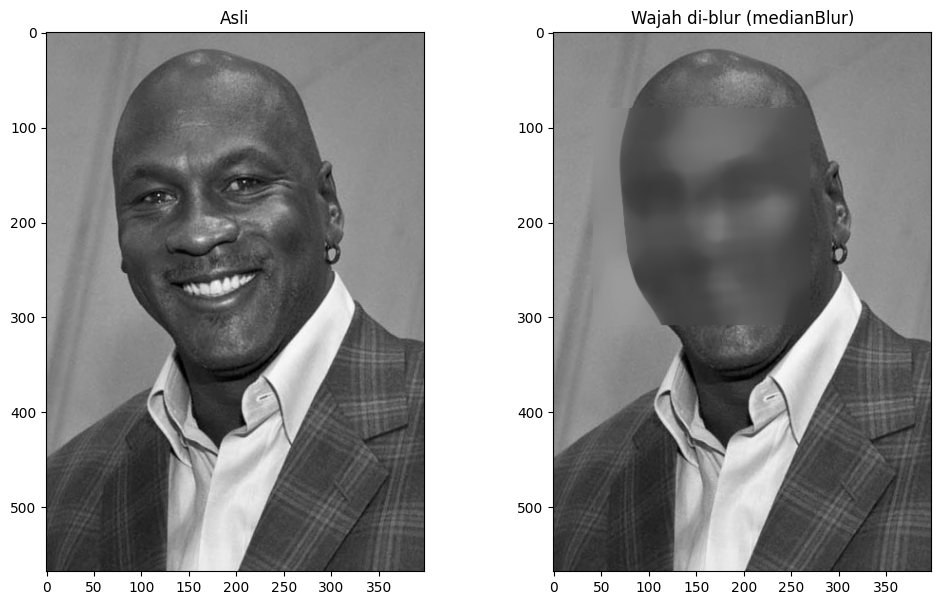

In [ ]:
img = cv.imread(cari('mjordan.jpg'), cv.IMREAD_GRAYSCALE)
blur = img.copy()
faces = cascade_wajah.detectMultiScale(img)
for (x, y, w, h) in faces:
    k = max(15, (w // 5) | 1)
    blur[y:y + h, x:x + w] = cv.medianBlur(blur[y:y + h, x:x + w], k)
print('Wajah diblur:', len(faces))

plt.figure(figsize=(12, 7))
plt.subplot(1, 2, 1), plt.imshow(img, cmap='gray'), plt.title('Asli')
plt.subplot(1, 2, 2), plt.imshow(blur, cmap='gray'), plt.title('Wajah di-blur (medianBlur)')
plt.show()

## 14. Mengolah gambar KTM


### Menampilkan foto pada KTM
Wajah pada KTM dideteksi dengan Haar Cascade. Kotak wajah lalu diperluas mengikuti proporsi pas foto (kepala, bahu, dan latar foto), sehingga yang terpotong adalah **foto KTM**, bukan hanya wajahnya.

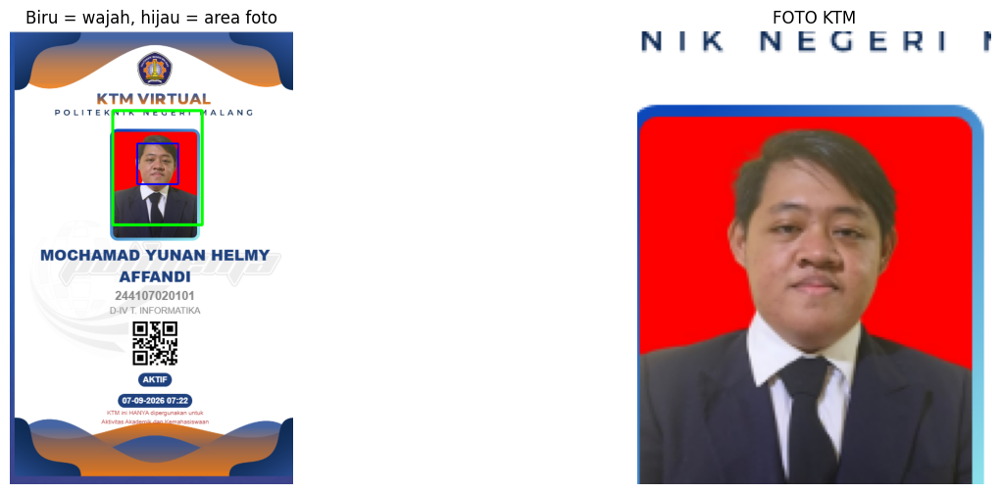

In [ ]:
ktm = cv.imread(KTM_SAYA)
H, W = ktm.shape[:2]
gray_k = cv.cvtColor(ktm, cv.COLOR_BGR2GRAY)
faces = cascade_wajah.detectMultiScale(gray_k, scaleFactor=1.1, minNeighbors=5, minSize=(25, 25))
if len(faces) == 0:
    faces = cascade_wajah.detectMultiScale(gray_k, scaleFactor=1.05, minNeighbors=3, minSize=(20, 20))

if len(faces):
    x, y, w, h = max(faces, key=lambda f: f[2] * f[3])        # wajah terbesar = foto KTM
    X1, X2 = max(0, int(x - 0.6 * w)), min(W, int(x + w + 0.6 * w))
    Y1, Y2 = max(0, int(y - 0.8 * h)), min(H, int(y + h + 1.0 * h))
    foto = ktm[Y1:Y2, X1:X2]
    tanda = ktm.copy()
    cv.rectangle(tanda, (X1, Y1), (X2, Y2), (0, 255, 0), 3)
    cv.rectangle(tanda, (x, y), (x + w, y + h), (255, 0, 0), 2)
    plt.figure(figsize=(16, 6))
    plt.subplot(1, 2, 1), plt.imshow(rgb(tanda)), plt.title('Biru = wajah, hijau = area foto'), plt.axis('off')
    plt.subplot(1, 2, 2), plt.imshow(rgb(foto)), plt.title('FOTO KTM'), plt.axis('off')
    plt.show()
else:
    print('Wajah pada KTM tidak terdeteksi — coba KTM lain atau foto KTM yang lebih tajam.')

### c. Deteksi obyek KTM dengan Feature Matching
Pertama, contoh dari teori: **ORB** vs **SIFT** pada *reeses_puffs* dan *many_cereals*.

Hasil ORB banyak yang meleset karena ORB tidak tahan perbedaan skala yang besar. SIFT (*scale-invariant*) jauh lebih tepat mengarah ke kotak Reese's Puffs.


ORB: 1019 good match, 935 inlier RANSAC | rata-rata error pojok = 0.6 px


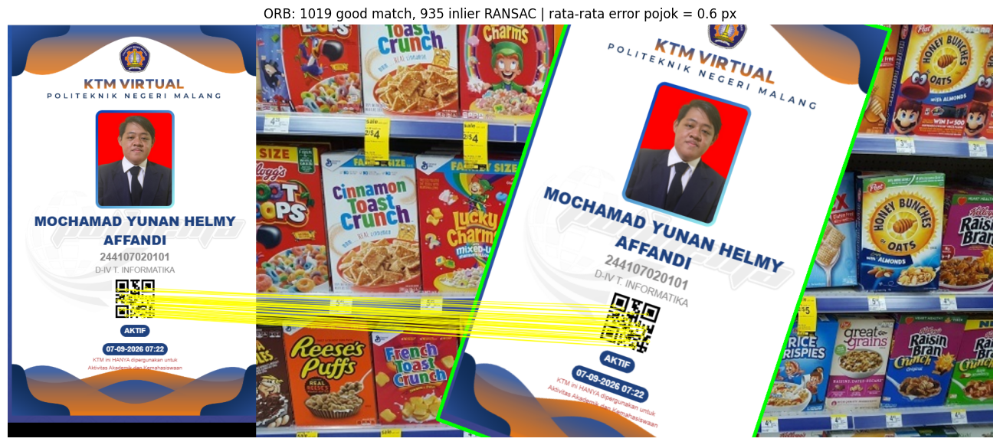

SIFT: 727 good match, 681 inlier RANSAC | rata-rata error pojok = 0.1 px


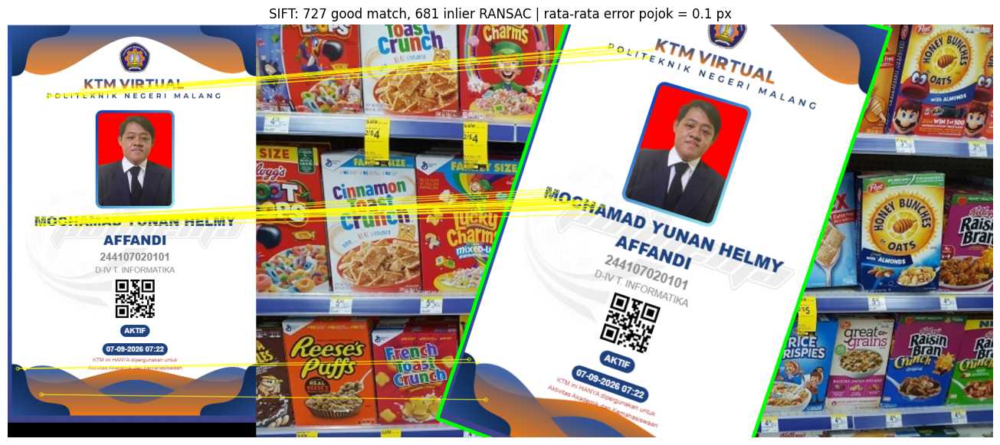

In [ ]:
SCENE_PATH = None

def buat_scene_sintetis(obj):
    bg = cv.imread(cari('many_cereals.jpg'))
    bg = cv.resize(bg, (1400, int(1400 * bg.shape[0] / bg.shape[1])))
    h, w = obj.shape[:2]
    s = 0.42 * bg.shape[1] / w
    hw, hh = w * s / 2, h * s / 2
    ang = np.deg2rad(18)
    R = np.array([[np.cos(ang), -np.sin(ang)], [np.sin(ang), np.cos(ang)]])
    sudut = np.array([[-hw, -hh], [hw, -hh], [hw, hh], [-hw, hh]]) @ R.T + [bg.shape[1] * 0.55, bg.shape[0] * 0.5]
    sudut[1] += [10, -25]; sudut[2] += [-15, 20]
    M = cv.getPerspectiveTransform(np.float32([[0, 0], [w, 0], [w, h], [0, h]]), np.float32(sudut))
    warp = cv.warpPerspective(obj, M, (bg.shape[1], bg.shape[0]))
    mask = cv.warpPerspective(np.full((h, w), 255, np.uint8), M, (bg.shape[1], bg.shape[0]))
    scene = bg.copy(); scene[mask > 0] = warp[mask > 0]
    return scene, np.float32(sudut)

ktm = cv.imread(KTM_SAYA)
if SCENE_PATH:
    scene, sudut_asli = cv.imread(SCENE_PATH), None
else:
    scene, sudut_asli = buat_scene_sintetis(ktm)

def cocokkan(detector, norm, obj, scn, ratio=0.75):
    k1, d1 = detector.detectAndCompute(cv.cvtColor(obj, cv.COLOR_BGR2GRAY), None)
    k2, d2 = detector.detectAndCompute(cv.cvtColor(scn, cv.COLOR_BGR2GRAY), None)
    pasang = cv.BFMatcher(norm).knnMatch(d1, d2, k=2)
    good = [p[0] for p in pasang if len(p) == 2 and p[0].distance < ratio * p[1].distance]
    H_, inl = None, None
    if len(good) >= 10:
        src = np.float32([k1[m.queryIdx].pt for m in good]).reshape(-1, 1, 2)
        dst = np.float32([k2[m.trainIdx].pt for m in good]).reshape(-1, 1, 2)
        H_, inl = cv.findHomography(src, dst, cv.RANSAC, 5.0)
    return k1, k2, good, H_, inl

h, w = ktm.shape[:2]
pojok = np.float32([[0, 0], [w, 0], [w, h], [0, h]]).reshape(-1, 1, 2)

for nama, det, norm in [('ORB', cv.ORB_create(3000), cv.NORM_HAMMING), ('SIFT', cv.SIFT_create(), cv.NORM_L2)]:
    k1, k2, good, H_, inl = cocokkan(det, norm, ktm, scene)
    hasil = scene.copy()
    info = f'{nama}: {len(good)} good match'
    if H_ is not None:
        kotak = cv.perspectiveTransform(pojok, H_)
        cv.polylines(hasil, [np.int32(kotak)], True, (0, 255, 0), 6)
        info += f', {int(inl.sum())} inlier RANSAC'
        if sudut_asli is not None:
            err = np.abs(kotak.reshape(4, 2) - sudut_asli).mean()
            info += f' | rata-rata error pojok = {err:.1f} px'
        inlier = [m for m, ok in zip(good, inl.ravel()) if ok][:40]
    else:
        info += ' (kurang dari 10, KTM tidak ditemukan)'
        inlier = good[:40]
    print(info)
    vis = cv.drawMatches(ktm, k1, hasil, k2, inlier, None, matchColor=(0, 255, 255), flags=2)
    plt.figure(figsize=(18, 7)); plt.imshow(rgb(vis)); plt.title(info); plt.axis('off'); plt.show()

## Kesimpulan D2
- **Haar Cascade (Viola-Jones)** cepat dan cukup akurat untuk wajah manusia frontal, termasuk lukisan, wajah kecil, dan sebagian wajah bermasker. Tetapi cascade hanya mengenali objek yang dilatih untuknya: wajah kucing perlu \`frontalcatface_extended.xml\`.
- **Deteksi bertingkat** (wajah → mata/senyum di dalam ROI wajah) mengurangi false positive secara signifikan dibanding mencari mata/senyum di seluruh gambar.
- **Face tracking** di Colab memerlukan JavaScript untuk mengambil frame webcam dari browser. Deteksinya tetap memakai cascade yang sama per frame.
- **Blurring wajah** dengan \`medianBlur\` pada ROI hasil deteksi adalah dasar anonimisasi wajah (privasi).
- **Feature matching**: ORB cepat tapi lemah terhadap perubahan skala besar. **SIFT + ratio test + homography RANSAC** mampu menemukan KTM walaupun diperkecil, diputar, dan diberi perspektif, lengkap dengan kotak 4 sudutnya.

---
# D3. Tugas Pengayaan — Pengenalan Karakter KTM dengan CNN
Alur kerjanya:
1. **Siapkan data training** karakter 0–9 dan A–Z. Daripada memotong ratusan gambar satu per satu dengan image editor, karakter di-*render* otomatis dari beberapa font sans-serif tebal (mirip font KTM), lalu diberi augmentasi: rotasi, ketebalan, blur, dan noise. Hasilnya disimpan dengan struktur folder yang sama seperti di modul: \`dataset/training/<karakter>/\`.
2. **Persiapan training**: kode modul (pickle X, Y, kelas).
3. **Training**: arsitektur CNN dari modul.
4. **Testing**: baris teks KTM dicari dengan proyeksi horizontal, karakter dipotong dengan *connected components*, disimpan ke \`dataset/testing/<baris>/\`, lalu dikenali dengan kode testing dari modul.

Semua karakter (training maupun testing) dinormalisasi dengan fungsi yang sama: **karakter putih di latar hitam, dipotong rapat, diberi padding menjadi persegi, lalu di-resize 100×100**.

In [ ]:
import glob, random, shutil
from PIL import Image, ImageDraw, ImageFont

KELAS = list('0123456789ABCDEFGHIJKLMNOPQRSTUVWXYZ')
UKURAN = 100

def normalisasi_karakter(biner):
    """biner: uint8, karakter putih (255) di latar hitam -> 100x100 persegi terpusat."""
    ys, xs = np.where(biner > 0)
    if len(xs) == 0:
        return np.zeros((UKURAN, UKURAN), np.uint8)
    c = biner[ys.min():ys.max() + 1, xs.min():xs.max() + 1]
    h, w = c.shape
    sisi = int(max(h, w) * 1.25) + 2
    kanvas = np.zeros((sisi, sisi), np.uint8)
    y0, x0 = (sisi - h) // 2, (sisi - w) // 2
    kanvas[y0:y0 + h, x0:x0 + w] = c
    return cv.resize(kanvas, (UKURAN, UKURAN), interpolation=cv.INTER_AREA)

# font sans-serif yang tersedia di Colab (+ font bawaan matplotlib)
import matplotlib
kandidat = glob.glob('/usr/share/fonts/truetype/**/*.ttf', recursive=True) + \
           glob.glob(os.path.join(os.path.dirname(matplotlib.__file__), 'mpl-data/fonts/ttf/*.ttf'))
FONTS = sorted({f for f in kandidat if 'Sans' in os.path.basename(f) and 'Mono' not in f and 'Humor' not in f and 'Display' not in f and 'Oblique' not in f and 'Italic' not in f})
print(len(FONTS), 'font dipakai:', [os.path.basename(f) for f in FONTS])

4 font dipakai: ['DejaVuSans-Bold.ttf', 'DejaVuSans.ttf', 'LiberationSans-Bold.ttf', 'LiberationSans-Regular.ttf']


### 1. Membuat dataset training (\`dataset/training/<karakter>/\`)

Total gambar training: 3960


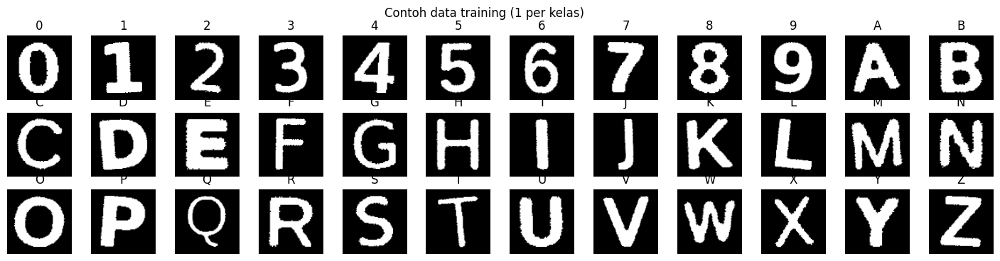

In [ ]:
random.seed(42); np.random.seed(42)
DATADIR_TRAIN = 'dataset/training'
PER_KELAS = 110

def render_karakter(ch):
    font = ImageFont.truetype(random.choice(FONTS), random.randint(60, 110))
    img = Image.new('L', (200, 200), 0)
    ImageDraw.Draw(img).text((100, 100), ch, fill=255, font=font, anchor='mm')
    a = np.array(img)
    M = cv.getRotationMatrix2D((100, 100), random.uniform(-6, 6), random.uniform(0.9, 1.1))
    a = cv.warpAffine(a, M, (200, 200))
    op = random.choice(['tebal', 'tipis', None, None])                # variasi ketebalan goresan
    if op == 'tebal':
        a = cv.dilate(a, np.ones((random.randint(2, 6),) * 2, np.uint8))
    elif op == 'tipis':
        a = cv.erode(a, np.ones((3, 3), np.uint8))
    if random.random() < 0.85:                                         # simulasi teks kecil KTM (10-20 px) yang diperbesar 3x
        kecil = random.randint(30, 70)
        a = cv.resize(cv.resize(a, (kecil, kecil), interpolation=cv.INTER_AREA), (200, 200), interpolation=cv.INTER_CUBIC)
    else:
        a = cv.GaussianBlur(a, (random.choice([1, 3, 5]),) * 2, 0)
    a = np.clip(a + np.random.normal(0, 12, a.shape), 0, 255).astype(np.uint8)
    _, a = cv.threshold(a, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)
    return normalisasi_karakter(a)

shutil.rmtree(DATADIR_TRAIN, ignore_errors=True)
for ch in KELAS:
    os.makedirs(os.path.join(DATADIR_TRAIN, ch), exist_ok=True)
    for i in range(PER_KELAS):
        cv.imwrite(os.path.join(DATADIR_TRAIN, ch, f'{ch}_{i:03d}.png'), render_karakter(ch))
print('Total gambar training:', len(KELAS) * PER_KELAS)

plt.figure(figsize=(18, 4))
for i, ch in enumerate(KELAS):
    plt.subplot(3, 12, i + 1)
    plt.imshow(cv.imread(os.path.join(DATADIR_TRAIN, ch, f'{ch}_000.png'), 0), cmap='gray'); plt.title(ch); plt.axis('off')
plt.suptitle('Contoh data training (1 per kelas)'); plt.show()

### 2. Persiapan data training (kode modul)

In [ ]:
import os
import cv2
import random
import numpy as np
import pickle
from tqdm import tqdm

DATADIR = "dataset/training"      # satu subfolder per karakter: 0..9, A..Z
width, height = 100, 100

dirs = sorted(os.listdir(DATADIR))        # daftar nama kelas
training_data = []

for char_name in dirs:
    path = os.path.join(DATADIR, char_name)
    class_number = dirs.index(char_name)
    for img in tqdm(os.listdir(path), desc=char_name):
        try:
            img_array = cv2.imread(os.path.join(path, img),
                                   cv2.IMREAD_GRAYSCALE)
            new_array = cv2.resize(img_array, (width, height))
            training_data.append([new_array, class_number])
        except Exception:
            pass

random.shuffle(training_data)

X, Y = [], []
for feature, label in training_data:
    X.append(feature)
    Y.append(label)

X = np.array(X).reshape(-1, width, height, 1)
Y = np.array(Y)

pickle.dump(X,    open("X.pickle", "wb"))
pickle.dump(Y,    open("Y.pickle", "wb"))
pickle.dump(dirs, open("kelas.pickle", "wb"))

print("jumlah data :", len(training_data))
print("jumlah kelas:", len(dirs), dirs)

Z: 100%|██████████| 110/110 [00:00<00:00, 4689.28it/s]


jumlah data : 3960
jumlah kelas: 36 ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9', 'A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z']


### 3. Training CNN (arsitektur modul)
Arsitektur sama persis dengan modul. Dua penyesuaian: `learning_rate` dinaikkan dari 0.0001 ke **0.001** (dengan 0.0001 akurasi validasi mentok di ~84.6% karena beberapa kelas tidak pernah terpisah), dan `EarlyStopping` dipasang (berhenti bila akurasi validasi tidak naik 3 epoch, memakai bobot terbaik) supaya training di CPU tidak terlalu lama.

Epoch 1/20
99/99 ━━━━━━━━━━━━━━━━━━━━ 54s 526ms/step - accuracy: 0.8365 - loss: 0.5993 - val_accuracy: 0.9962 - val_loss: 0.0159
Epoch 2/20
99/99 ━━━━━━━━━━━━━━━━━━━━ 55s 558ms/step - accuracy: 0.9915 - loss: 0.0367 - val_accuracy: 0.9987 - val_loss: 0.0079
Epoch 3/20
99/99 ━━━━━━━━━━━━━━━━━━━━ 53s 533ms/step - accuracy: 0.9984 - loss: 0.0054 - val_accuracy: 0.9987 - val_loss: 0.0063
Epoch 4/20
99/99 ━━━━━━━━━━━━━━━━━━━━ 54s 547ms/step - accuracy: 0.9994 - loss: 0.0022 - val_accuracy: 0.9987 - val_loss: 0.0062
Epoch 5/20
99/99 ━━━━━━━━━━━━━━━━━━━━ 80s 524ms/step - accuracy: 0.9905 - loss: 0.0466 - val_accuracy: 0.9672 - val_loss: 0.4636
akurasi training  : 0.9905303120613098
akurasi validasi  : 0.9671717286109924


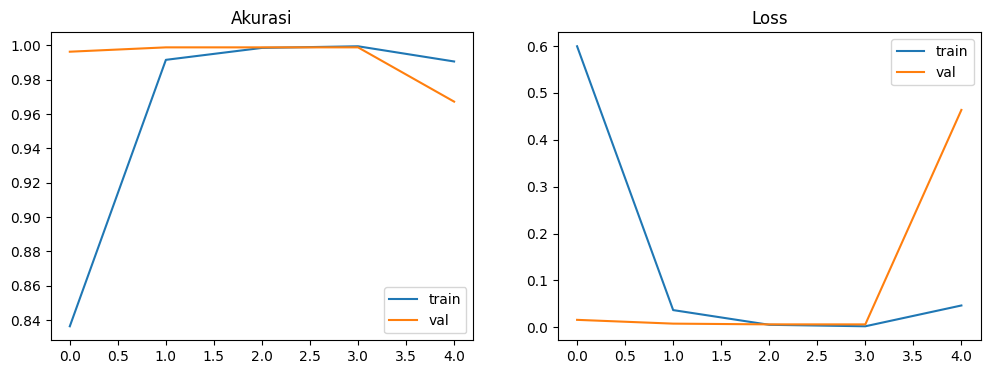

In [ ]:
import pickle
from keras.layers import (Input, Conv2D, MaxPooling2D,
                          Flatten, Dense, ZeroPadding2D)
from keras.models import Model
from keras.optimizers import Adam
from keras.utils import to_categorical
from keras.callbacks import EarlyStopping

X = pickle.load(open("X.pickle", "rb"))
Y = pickle.load(open("Y.pickle", "rb"))

Y = to_categorical(Y)
X = X / 255.0
width, height = 100, 100
jumlah_kelas = Y.shape[1]          # diambil dari data, tidak ditulis tetap

inputs     = Input(shape=(width, height, 1))
conv_layer = ZeroPadding2D(padding=(2, 2))(inputs)
conv_layer = Conv2D(16, (5, 5), strides=(1, 1), activation='relu')(conv_layer)
conv_layer = MaxPooling2D((2, 2))(conv_layer)
conv_layer = Conv2D(32, (3, 3), strides=(1, 1), activation='relu')(conv_layer)
conv_layer = Conv2D(32, (3, 3), strides=(1, 1), activation='relu')(conv_layer)
conv_layer = MaxPooling2D((2, 2))(conv_layer)
conv_layer = Conv2D(64, (3, 3), strides=(1, 1), activation='relu')(conv_layer)

flaten   = Flatten()(conv_layer)
fc_layer = Dense(256, activation='relu')(flaten)
fc_layer = Dense(64,  activation='relu')(fc_layer)
outputs  = Dense(jumlah_kelas, activation='softmax')(fc_layer)

model = Model(inputs=inputs, outputs=outputs)
# modul memakai learning_rate=0.0001; pada data ini akurasi validasi mentok ~84.6% sejak epoch 3,
# sehingga dinaikkan ke 0.001 agar model benar-benar membedakan semua 36 kelas
model.compile(optimizer=Adam(learning_rate=0.001),
              loss='categorical_crossentropy',
              metrics=['accuracy'])

stop = EarlyStopping(monitor='val_accuracy', patience=3, restore_best_weights=True)
riwayat = model.fit(X, Y, epochs=20, verbose=1, validation_split=0.2, callbacks=[stop])
model.save('anpr.keras')

print("akurasi training  :", riwayat.history['accuracy'][-1])
print("akurasi validasi  :", riwayat.history['val_accuracy'][-1])

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1); plt.plot(riwayat.history['accuracy'], label='train'); plt.plot(riwayat.history['val_accuracy'], label='val'); plt.title('Akurasi'); plt.legend()
plt.subplot(1, 2, 2); plt.plot(riwayat.history['loss'], label='train'); plt.plot(riwayat.history['val_loss'], label='val'); plt.title('Loss'); plt.legend()
plt.show()

### 4. Segmentasi karakter dari KTM → \`dataset/testing/<baris>/\`
1. Ambil area teks KTM (nama, NIM, prodi), lalu grayscale dan threshold Otsu *inverse* (teks gelap → putih).
2. **Proyeksi horizontal**: baris teks = rentang baris piksel yang berisi tinta.
3. Tiap baris diproses dengan **connected components**, lalu diurutkan dari kiri ke kanan. Komponen yang terlalu kecil (titik, strip) dibuang, dan komponen yang terlalu lebar (huruf menempel) dibelah.
4. Jarak antar karakter yang lebar dianggap spasi.

Ukuran KTM: (757, 472, 3)
Baris teks ditemukan: 4 [(39, 93), (147, 201), (246, 291), (327, 360)]


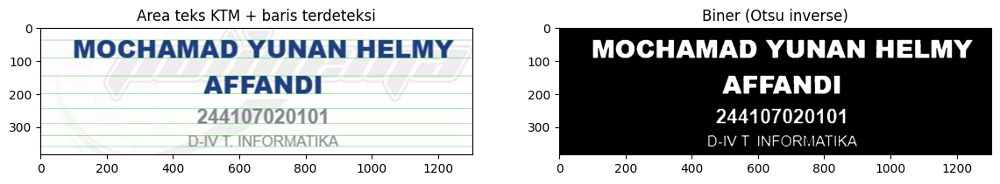

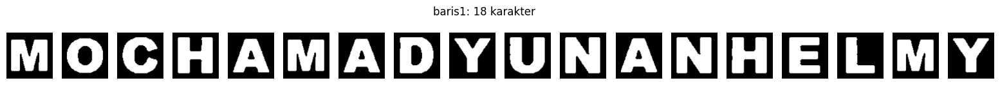

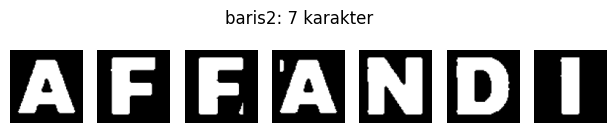

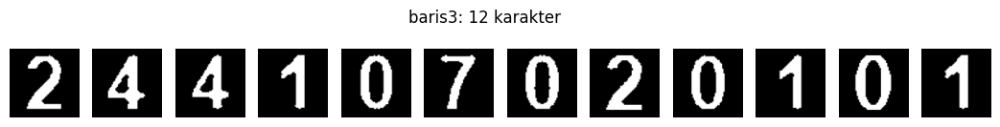

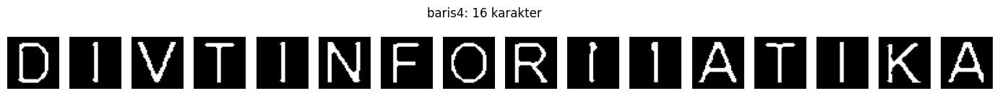

In [ ]:
ktm_d = cv.imread(cari('KTMd.png'))
H, W = ktm_d.shape[:2]
y1, y2 = int(0.465 * H), int(0.635 * H)           # area nama, NIM, dan prodi (di bawah foto, di atas QR)
print('Ukuran KTM:', ktm_d.shape)
area = ktm_d[y1:y2, int(0.04 * W):int(0.96 * W)]
area = cv.resize(area, None, fx=3, fy=3, interpolation=cv.INTER_CUBIC)   # perbesar 3x agar goresan tipis (M, 1) tidak putus
g = cv.cvtColor(area, cv.COLOR_BGR2GRAY)
_, bw = cv.threshold(g, 0, 255, cv.THRESH_BINARY_INV + cv.THRESH_OTSU)
bw = cv.morphologyEx(bw, cv.MORPH_CLOSE, cv.getStructuringElement(cv.MORPH_ELLIPSE, (3, 3)))   # sambung goresan tipis yang putus

# proyeksi horizontal -> baris teks
proj = (bw > 0).sum(axis=1)
ada = proj > 6
baris, mulai = [], None
for i, v in enumerate(np.append(ada, False)):
    if v and mulai is None:
        mulai = i
    elif not v and mulai is not None:
        if i - mulai >= 24:
            baris.append((mulai, i))
        mulai = None
print('Baris teks ditemukan:', len(baris), baris)

DATADIR_TEST = 'dataset/testing'
shutil.rmtree(DATADIR_TEST, ignore_errors=True)
HASIL_SEGMEN = {}

for nb, (a, b) in enumerate(baris, 1):
    line = bw[a:b]
    n, lab, st, _ = cv.connectedComponentsWithStats(line, 8)
    kotak = [tuple(st[i, :4]) for i in range(1, n) if st[i, 3] >= 0.55 * (b - a)]   # buang titik/strip
    kotak.sort(key=lambda k: k[0])
    if not kotak:
        continue
    pecah = []
    for (x, y, w, h) in kotak:                       # belah huruf menempel: huruf normal (termasuk M/W) lebarnya <= ~1.25x tinggi
        k = max(1, int(round(w / (0.8 * h)))) if w > 1.25 * h else 1
        for j in range(k):
            pecah.append((x + j * w // k, y, w // k, h))
    folder = os.path.join(DATADIR_TEST, f'baris{nb}')
    os.makedirs(folder, exist_ok=True)
    spasi, crops = [], []
    for idx, (x, y, w, h) in enumerate(pecah):
        crop = np.zeros_like(line[:, x:x + w]); crop[:] = line[:, x:x + w]
        img_n = normalisasi_karakter(crop)
        cv.imwrite(os.path.join(folder, f'{idx:02d}.png'), img_n)
        crops.append(img_n)
        if idx > 0 and x - (pecah[idx - 1][0] + pecah[idx - 1][2]) > 0.45 * (b - a):
            spasi.append(idx)
    HASIL_SEGMEN[f'baris{nb}'] = (crops, spasi)

vis = area.copy()
for (a, b) in baris:
    cv.rectangle(vis, (0, a), (vis.shape[1] - 1, b), (0, 200, 0), 1)
plt.figure(figsize=(14, 6))
plt.subplot(1, 2, 1); plt.imshow(rgb(vis)); plt.title('Area teks KTM + baris terdeteksi')
plt.subplot(1, 2, 2); plt.imshow(bw, cmap='gray'); plt.title('Biner (Otsu inverse)')
plt.show()
for nama, (crops, _) in HASIL_SEGMEN.items():
    plt.figure(figsize=(len(crops) * 1.1, 1.6))
    for i, c in enumerate(crops):
        plt.subplot(1, len(crops), i + 1); plt.imshow(c, cmap='gray'); plt.axis('off')
    plt.suptitle(f'{nama}: {len(crops)} karakter'); plt.show()

### 5. Testing (kode modul) dan evaluasi

In [ ]:
import os
import cv2
import pickle
import numpy as np
import tensorflow as tf

data_dir_testing = "dataset/testing"
width, height = 100, 100

model = tf.keras.models.load_model("anpr.keras")
dirs  = pickle.load(open("kelas.pickle", "rb"))       # urutan kelas saat training

HASIL = {}
for car in sorted(os.listdir(data_dir_testing)):
    temp = ""
    folder = os.path.join(data_dir_testing, car)
    for char_img in sorted(os.listdir(folder)):
        img_array = cv2.imread(os.path.join(folder, char_img),
                               cv2.IMREAD_GRAYSCALE)
        new_array = cv2.resize(img_array, (width, height))
        new_array = new_array.reshape(-1, width, height, 1) / 255.0
        prediction = model.predict(new_array, verbose=0)
        temp += dirs[np.argmax(prediction[0])]
    HASIL[car] = temp
    print("folder name: {} no: {}".format(car, temp))

folder name: baris1 no: MOCHAMADYUNANHELMY
folder name: baris2 no: AFFANDI
folder name: baris3 no: 244407020404
folder name: baris4 no: DIVTINFORIIATIKA


In [ ]:
from difflib import SequenceMatcher

# label sebenarnya, dibaca manual dari KTM (tanda baca '-' dan '.' tidak ikut disegmentasi)
LABEL = ['MOCHAMAD YUNAN HELMY', 'AFFANDI', '244107020101', 'DIV T INFORMATIKA']
idx_angka = [i for i, k in enumerate(dirs) if k.isdigit()]
idx_huruf = [i for i, k in enumerate(dirs) if k.isalpha()]

def prediksi_baris(folder, pakai_konteks):
    files = sorted(os.listdir(folder))
    X_ = np.array([cv2.resize(cv2.imread(os.path.join(folder, f), 0), (width, height)) for f in files]).reshape(-1, width, height, 1) / 255.0
    P = model.predict(X_, verbose=0)
    if not pakai_konteks:
        return ''.join(dirs[i] for i in P.argmax(1))
    # konteks: baris yang peluang total angkanya > huruf hanya boleh berisi angka (mis. NIM), dan sebaliknya
    angka = P[:, idx_angka].sum(1).mean() > P[:, idx_huruf].sum(1).mean()
    idx = idx_angka if angka else idx_huruf
    return ''.join(dirs[idx[j]] for j in P[:, idx].argmax(1))

def evaluasi(pakai_konteks):
    benar_total = n_total = 0
    judul = 'DENGAN konteks baris' if pakai_konteks else 'TANPA konteks (murni CNN)'
    print(f'=== {judul} ===')
    print(f'{"baris":8s} | {"hasil CNN":24s} | {"label":24s} | benar')
    print('-' * 72)
    for i, car in enumerate(sorted(os.listdir(data_dir_testing))):
        _, spasi = HASIL_SEGMEN[car]
        raw = prediksi_baris(os.path.join(data_dir_testing, car), pakai_konteks)
        pred = ''.join((' ' if j in spasi else '') + c for j, c in enumerate(raw))
        label = LABEL[i] if i < len(LABEL) else ''
        a, b = raw, label.replace(' ', '')
        benar = sum(blk.size for blk in SequenceMatcher(None, a, b).get_matching_blocks())
        benar_total += benar; n_total += max(len(a), len(b))
        print(f'{car:8s} | {pred:24s} | {label:24s} | {benar}/{max(len(a), len(b))}')
    print('-' * 72)
    print(f'Akurasi karakter: {benar_total}/{n_total} = {100 * benar_total / max(n_total, 1):.1f}%\n')

evaluasi(False)
evaluasi(True)

=== TANPA konteks (murni CNN) ===
baris    | hasil CNN                | label                    | benar
------------------------------------------------------------------------
baris1   | MOCHAMAD YUNAN HELMY     | MOCHAMAD YUNAN HELMY     | 18/18
baris2   | AFFANDI                  | AFFANDI                  | 7/7
baris3   | 244407020404             | 244107020101             | 9/12
baris4   | D IVT INFORI IATIKA      | DIV T INFORMATIKA        | 14/16
------------------------------------------------------------------------
Akurasi karakter: 48/53 = 90.6%

=== DENGAN konteks baris ===
baris    | hasil CNN                | label                    | benar
------------------------------------------------------------------------
baris1   | MOCHAMAD YUNAN HELMY     | MOCHAMAD YUNAN HELMY     | 18/18
baris2   | AFFANDI                  | AFFANDI                  | 7/7
baris3   | 244407020404             | 244107020101             | 9/12
baris4   | D IVT INFORI IATIKA      | DIV T INFORMAT

### Kesimpulan D3
- CNN dengan arsitektur modul dilatih **tanpa satu pun gambar dari KTM** (seluruhnya data sintetis hasil render font + augmentasi), lalu diuji pada karakter yang dipotong otomatis dari KTM digital Mochamad Yunan Helmy Affandi.
- Kunci keberhasilannya adalah **normalisasi yang identik** antara data training dan testing: putih di atas hitam, dipotong rapat, persegi, dan 100×100.
- Kesalahan yang paling mungkin terjadi adalah pada pasangan karakter yang bentuknya hampir sama di font sans-serif tebal, seperti **0/O**, **1/I**, **5/S**, dan **8/B**. Solusinya bisa dengan menambahkan konteks: baris NIM pasti angka, dan baris nama pasti huruf.
- Segmentasi berbasis proyeksi dan connected components bekerja baik untuk KTM digital yang bersih. Untuk foto KTM (miring, buram) perlu rektifikasi perspektif dulu, misalnya dengan homography seperti di nomor 14c.